# Full-feature correlation and multicollinearity audit

Saved outputs audit the former 177-input schema. Run All with the project `.venv` kernel to evaluate the current 148 inputs. This read-only diagnostic produces retain/review/exclusion-candidate tables; it does not select training features automatically.

The historical run profiled 1,660,076 fitting listings and sampled 30,000 for diagnostics: 584 strong numeric pairs, 14 strong categorical pairs, and two constant-input candidates. Numerical rank was 146/205 for numeric-plus-missingness and 340/416 for the pooled mixed design. Detailed pair/design tables and the final review retain the evidence.

## Methods and interpretation

Use the production loader and cohort-stratified VIN split; validation/test values and price stay outside the diagnostic design. All four decoded cohort columns remain separate. Full-fit profiles establish constants/missingness; a deterministic fit-only sample supplies pair/design diagnostics.

Pearson/Spearman and categorical/mixed associations use observed pairs; VIF uses the separately imputed design. VIF is `1/(1-R²)` with an intercept; singular directions yield infinite VIF. VIF 5/10 and condition index 30 are review heuristics. Per-variant designs share rows; the mixed design approximates production category encoding.

Listings repeat make/family aggregates. IID-only p-values and BH q-values cannot establish significance for those repeated observations; the YouTube sensitivity weights makes equally. Some perfect correlations have only two observed makes. Imputation, coverage, and cardinality can shape dependencies. Confirm source equality and matched validation performance before removing fields.

References: [VIF](https://www.statsmodels.org/dev/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html), [Spearman caveats](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mstats.spearmanr.html), [correlated-feature interpretation](https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance_multicollinear.html).


### 1. Setup and parameters
Use the dependencies in `requirements.txt`. Start from the checkout root or `MODELS`. Each execution creates a fresh ignored `MODEL_OUTPUT/multicollinearity/<timestamp>/`; source tables and existing models are read-only.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc, hashlib, importlib.metadata, json, sys
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'MODELS/Price_ML_Models.py').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'MODELS/Price_ML_Models.py').is_file():
    raise FileNotFoundError('Open from the project checkout.')
sys.path.insert(0, str(ROOT))
from MODELS import Price_ML_Models as price
from EDA.DATA_CLEANING import FINAL_DATASET_PATH, DEFAULT_COHORT_REVIEW_DIR

MAX_DIAGNOSTIC_ROWS = 30_000  # None: all fit rows. Full loading/splitting always precedes sampling.
MIN_PAIR_ROWS = 100
CORRELATION_THRESHOLD = 0.90
ASSOCIATION_THRESHOLD = 0.90
VIF_REVIEW, VIF_HIGH = 5., 10.
MAX_CATEGORY_LEVELS = 12  # Mixed VIF only; includes pooled infrequent level.
MAX_MIXED_COLUMNS = 1000  # Fail visibly if exceeded; never silently skip a field.
SEED = price.RANDOM_SEED
EXPERT_DIR, YOUTUBE_DIR = price.EXPERT_FEATURE_DIRECTORY, price.YOUTUBE_FEATURE_DIRECTORY
RUN = ROOT / 'MODEL_OUTPUT/multicollinearity' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({'figure.dpi':110, 'font.size':11, 'axes.spines.top':False, 'axes.spines.right':False})
BLUE, GOLD = '#315E88', '#A76617'
def save_table(name, data):
    data.to_csv(RUN / f'{name}.csv', index=False)
def write_json(name, data):
    (RUN / name).write_text(json.dumps(data, indent=2, default=str, allow_nan=False), encoding='utf-8')
def show_figure(fig, name):
    fig.savefig(RUN / f'{name}.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
manifest = dict(status='running', created_at=datetime.now(timezone.utc).isoformat(), model_type='full',
                split='cohort_stratified', seed=SEED, max_diagnostic_rows=MAX_DIAGNOSTIC_ROWS,
                min_pair_rows=MIN_PAIR_ROWS, correlation_threshold=CORRELATION_THRESHOLD,
                association_threshold=ASSOCIATION_THRESHOLD, vif_review=VIF_REVIEW, vif_high=VIF_HIGH,
                max_category_levels=MAX_CATEGORY_LEVELS, max_mixed_columns=MAX_MIXED_COLUMNS,
                versions={p:importlib.metadata.version(p) for p in
                          ('numpy','pandas','polars','scipy','scikit-learn','matplotlib')})
write_json('manifest.json', manifest)
print('Output:', RUN)

Output: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\multicollinearity\20261028T020827206815Z


## Data
### 2. Load the selected full inputs and bind source lineage
Use the complete eligible population before splitting. Hash sources, enrichment exports, loader code and the selected cohort exclusion policy. Stop if inputs change during loading.

In [2]:
review_paths = sorted(DEFAULT_COHORT_REVIEW_DIR.glob('*/cohort_outlier_candidates.csv'))
if not review_paths:
    raise FileNotFoundError('Run the existing cohort price/mileage review first; see README.')
review_path = review_paths[-1]
source_paths = [FINAL_DATASET_PATH / f for f in ('used_cars.parquet','NHTSA_vPIC.parquet',
                 'NHTSA_Complaints.parquet','NHTSA_Recalls.parquet','NHTSA_Safety.parquet')]
source_paths += [YOUTUBE_DIR / f for f in ('make_features.parquet','price_feature_manifest.json')]
source_paths += [EXPERT_DIR / f for f in ('cohort_features.parquet','make_features.parquet',
                                        'expert_feature_manifest.json','review_resolution.parquet')]
source_paths.append(review_path)
source_stats = {str(p):(p.stat().st_size,p.stat().st_mtime_ns) for p in source_paths}
manifest['source_sha256'] = {str(p):price.file_sha256(p) for p in source_paths}
manifest['code_sha256'] = {p:price.file_sha256(ROOT / p) for p in price.PRICE_CODE_FILES}
manifest['notebook_sha256'] = price.file_sha256(ROOT / 'MODELS/Full_Feature_Multicollinearity.ipynb')
frame, data_info = price.load_model_frame('full', None, expert_feature_dir=EXPERT_DIR, youtube_feature_dir=YOUTUBE_DIR)
if any((p.stat().st_size,p.stat().st_mtime_ns) != source_stats[str(p)] for p in source_paths):
    raise RuntimeError('A source changed during loading; rerun with stable inputs.')
if sorted(DEFAULT_COHORT_REVIEW_DIR.glob('*/cohort_outlier_candidates.csv'))[-1] != review_path:
    raise RuntimeError('The cohort exclusion policy changed during loading.')
features = list(price.MODEL_FEATURE_SETS['full'])
assert len(features) == len(set(features))
assert not set(features) & {'price','vin','VIN','_cohort_group',*price.COHORT_COLUMNS}
categorical = [c for c in features if frame.schema[c] == pl.String]
numeric = [c for c in features if c not in categorical]
write_json('data_info.json', data_info)
print(f'{frame.height:,} eligible listings; {len(features)} inputs: {len(numeric)} numeric/binary, {len(categorical)} categorical.')

2,792,993 eligible listings; 177 inputs: 127 numeric/binary, 50 categorical.


### 3. Reproduce production VIN partitions, then sample fitting rows
Only VIN/cohort keys enter splitting. Full-fit support distinguishes dataset-wide constants from sample-only degeneracy. Sampling is target-independent and deterministic. Partition receipts retain separate decoded cohort keys.

In [3]:
identity = frame.select('vin',*price.COHORT_COLUMNS,'_cohort_group').to_pandas()
identity, fit_idx, val_idx, test_idx, split_info, split_audit = price.split_stratified_cohorts(identity)
assert not identity.vin.duplicated().any()
partition = np.full(len(identity),'fit',dtype='<U10')
partition[val_idx], partition[test_idx] = 'validation','test'
identity['partition'] = partition
receipt = identity.rename(columns={'_cohort_group':'split_group'})
receipt.to_parquet(RUN / 'split_manifest.parquet', index=False)
save_table('cohort_split_audit',split_audit)
assert len(fit_idx)+len(val_idx)+len(test_idx) == len(identity)
assert not set(fit_idx)&set(val_idx) and not set(fit_idx)&set(test_idx) and not set(val_idx)&set(test_idx)
manifest['split_details'] = split_info
manifest['split_fingerprint'] = price.split_fingerprint(receipt)
fit_frame = frame.filter(pl.col('vin').is_in(identity.iloc[fit_idx].vin.tolist()))
assert fit_frame.height == len(fit_idx)
del frame, identity, receipt
fit_frame = fit_frame.with_columns([pl.when(pl.col(c).cast(pl.Float64).is_finite()).then(pl.col(c).cast(pl.Float64)).otherwise(None).alias(c) for c in numeric])
profile_rows = []
for c in features:
    s = fit_frame[c]
    unique = s.drop_nulls().n_unique()
    status = ('all_missing' if s.count()==0 else 'constant_including_missingness' if unique==1 and s.null_count()==0
              else 'constant_observed_with_missingness' if unique==1 else 'variable')
    profile_rows.append(dict(field=c,kind='categorical' if c in categorical else 'numeric/binary',
                            fit_observed=s.count(),fit_missing_share=s.null_count()/fit_frame.height,
                            fit_distinct_observed=unique,fit_status=status))
profile = pd.DataFrame(profile_rows).set_index('field')
count = fit_frame.height if MAX_DIAGNOSTIC_ROWS is None else min(MAX_DIAGNOSTIC_ROWS,fit_frame.height)
sample = fit_frame.with_columns(pl.col('vin').hash(seed=SEED).alias('_order')).sort('_order').head(count)
sample.select('vin',*price.COHORT_COLUMNS).write_parquet(RUN / 'diagnostic_vins.parquet')
X = sample.select(features).to_pandas()
make_keys = sample['Make'].to_pandas().astype('string').str.strip().str.upper()
assert sample['vin'].is_in(fit_frame['vin'].implode()).all()
manifest.update(fit_rows=fit_frame.height,diagnostic_rows=len(X),predictors=len(features),
                categorical_fields=categorical,numeric_fields=numeric)
profile['sample_distinct_observed'] = [X[c].nunique(dropna=True) for c in profile.index]
save_table('feature_profile',profile.reset_index())
del sample, fit_frame
gc.collect()
display(pd.DataFrame({'partition':['fit','validation','test','diagnostic sample'],
                      'rows':[len(fit_idx),len(val_idx),len(test_idx),len(X)]}))
display(profile.groupby(['kind','fit_status']).size().rename('fields').to_frame())
write_json('manifest.json',manifest)

,partition,rows
0,fit,1660076
1,validation,550540
2,test,550540
3,diagnostic sample,30000


fields
kind           fit_status                                
categorical    constant_observed_with_missingness       3
               variable                                47
numeric/binary constant_including_missingness           2
               constant_observed_with_missingness       1
               variable                               124

## Results
### 4. Pairwise observed Pearson and Spearman tests
Export all numeric/binary pairs with overlap and missingness correlation; leave low-support estimates unavailable. Pearson's beta-null and Spearman's large-sample t p-values are IID-only reference calculations. BH q-values adjust each test family separately. **Do not interpret these as valid significance tests for repeated listings or make/family aggregates.** Pairwise deletion means correlations can describe different populations. No price-correlation filter is applied.

In [4]:
def bh_adjust(values):
    values = np.asarray(values,dtype=float)
    result = np.full(len(values),np.nan)
    valid = np.flatnonzero(np.isfinite(values))
    order = valid[np.argsort(values[valid])]
    if len(order):
        adjusted = values[order]*len(order)/np.arange(1,len(order)+1)
        result[order] = np.minimum(1,np.minimum.accumulate(adjusted[::-1])[::-1])
    return result
numbers = X[numeric].replace([np.inf,-np.inf],np.nan).astype(float)
pearson = numbers.corr(method='pearson',min_periods=MIN_PAIR_ROWS)
spearman = numbers.corr(method='spearman',min_periods=MIN_PAIR_ROWS)
observed = numbers.notna().to_numpy(dtype=np.int64)
overlap = observed.T@observed
missing_corr = numbers.isna().astype(float).corr()
upper = np.triu_indices(len(numeric),1)
pairs = pd.DataFrame(dict(field_a=np.asarray(numeric)[upper[0]],field_b=np.asarray(numeric)[upper[1]],
    observed_pairs=overlap[upper],pearson=pearson.to_numpy()[upper],spearman=spearman.to_numpy()[upper],
    missingness_pearson=missing_corr.to_numpy()[upper]))
pairs['overlap_share'] = pairs.observed_pairs/len(X)
n = pairs.observed_pairs.to_numpy()
valid = n >= max(3,MIN_PAIR_ROWS)
r, rho = pairs.pearson.abs().clip(0,1).to_numpy(),pairs.spearman.abs().clip(0,1).to_numpy()
pearson_p, spearman_p = np.full(len(pairs),np.nan),np.full(len(pairs),np.nan)
pearson_p[valid] = 2*stats.beta.cdf((1-r[valid])/2,n[valid]/2-1,n[valid]/2-1)
with np.errstate(divide='ignore',invalid='ignore'):
    t = rho[valid]*np.sqrt((n[valid]-2)/(1-rho[valid]**2))
spearman_p[valid] = 2*stats.t.sf(t,n[valid]-2)
pairs['pearson_p_iid_only'],pairs['spearman_p_iid_only'] = pearson_p,spearman_p
pairs['pearson_q_iid_only'],pairs['spearman_q_iid_only'] = bh_adjust(pearson_p),bh_adjust(spearman_p)
pairs['max_abs_correlation'] = pairs[['pearson','spearman']].abs().max(axis=1)
pairs = pairs.sort_values('max_abs_correlation',ascending=False)
strong_pairs = pairs.loc[pairs.max_abs_correlation.ge(CORRELATION_THRESHOLD)].copy()
save_table('numeric_pairs',pairs)
save_table('strong_numeric_pairs',strong_pairs)
pearson.to_csv(RUN / 'pearson_matrix.csv')
spearman.to_csv(RUN / 'spearman_matrix.csv')
display(strong_pairs[['field_a','field_b','observed_pairs','overlap_share','pearson','spearman']].head(25).round(3))

,field_a,field_b,observed_pairs,overlap_share,pearson,spearman
5741,yt_comment_count,yt_comfort_video_balanced_net,4672,0.156,-1.000,-1.0
5764,yt_comment_count,yt_comfort_video_balanced_soft_net,4672,0.156,-1.000,-1.0
5765,yt_comment_count,yt_comfort_mean_confidence,4672,0.156,-1.000,-1.0
5766,yt_comment_count,yt_comfort_mean_margin,4672,0.156,-1.000,-1.0
7811,yt_maintenance_cost_mean_confidence,yt_maintenance_cost_mean_margin,7662,0.255,1.000,1.0
7814,yt_maintenance_cost_mean_confidence,yt_reliability_video_balanced_soft_net,7662,0.255,0.948,1.0
7817,yt_maintenance_cost_mean_confidence,yt_reliability_mean_entropy,7662,0.255,-0.779,-1.0
7832,yt_maintenance_cost_mean_margin,yt_reliability_video_balanced_soft_net,7662,0.255,0.940,1.0
7835,yt_maintenance_cost_mean_margin,yt_reliability_mean_entropy,7662,0.255,-0.798,-1.0
5767,yt_comment_count,yt_comfort_mean_entropy,4672,0.156,1.000,1.0


### 5. Strong correlations and source-grain sensitivity
The heatmap is a readable subset; complete matrices remain exported. YouTube sensitivity uses one row per decoded Make, excludes absent identities and retains pairwise make counts. It describes the observed makes rather than independently validating the source opinions.

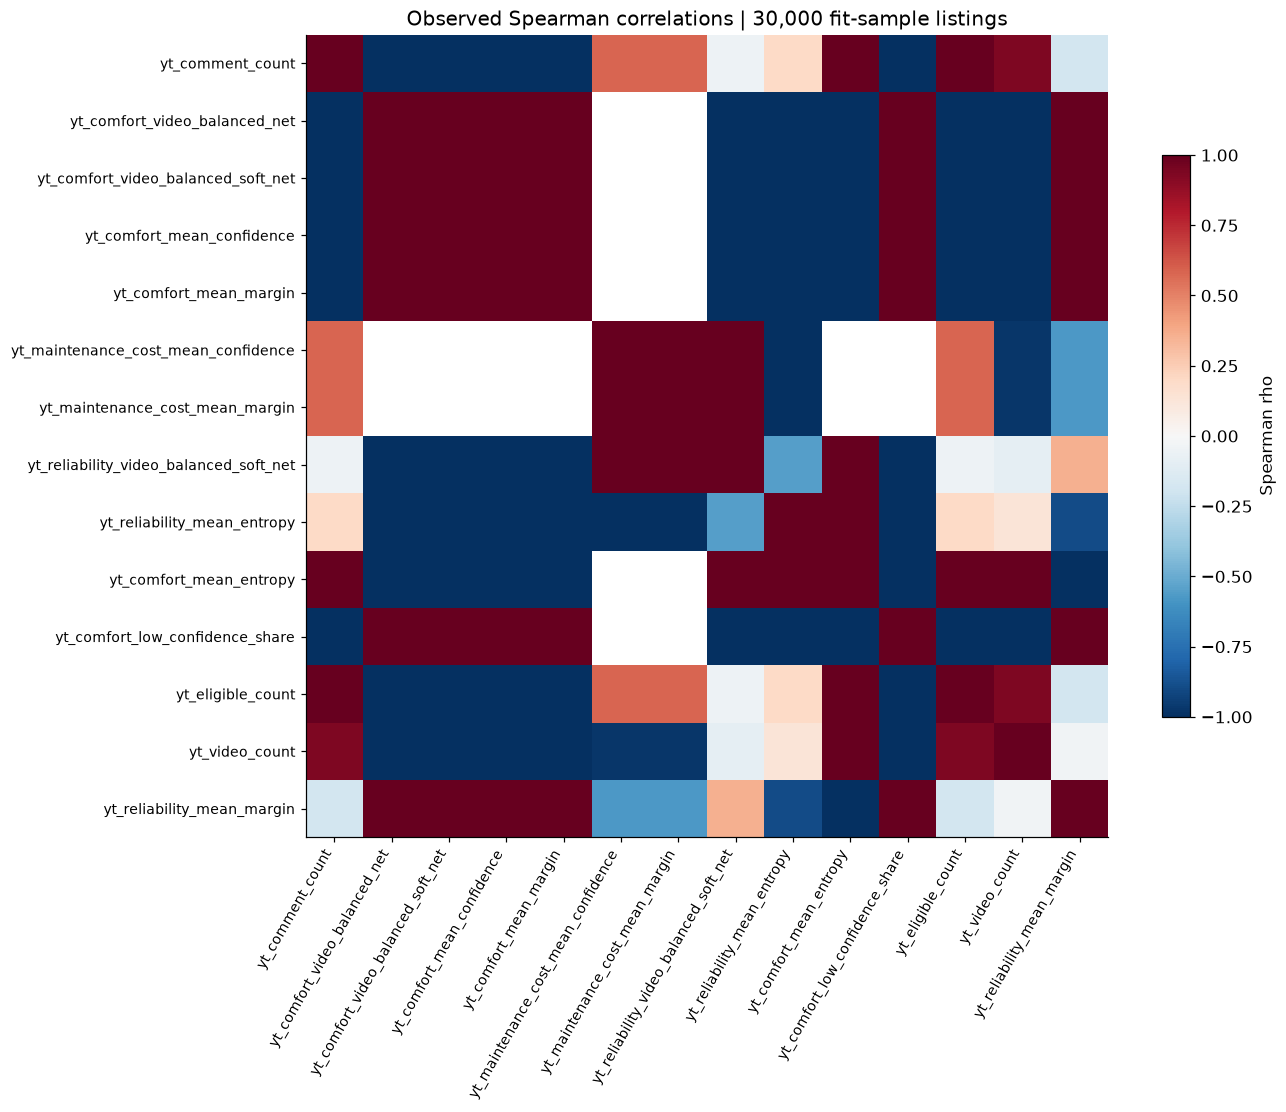

,field_a,field_b,observed_pairs,spearman,make_spearman,observed_make_pairs
5741,yt_comment_count,yt_comfort_video_balanced_net,4672,-1.0,NaN,2
5764,yt_comment_count,yt_comfort_video_balanced_soft_net,4672,-1.0,NaN,2
5765,yt_comment_count,yt_comfort_mean_confidence,4672,-1.0,NaN,2
5766,yt_comment_count,yt_comfort_mean_margin,4672,-1.0,NaN,2
7811,yt_maintenance_cost_mean_confidence,yt_maintenance_cost_mean_margin,7662,1.0,NaN,4
7814,yt_maintenance_cost_mean_confidence,yt_reliability_video_balanced_soft_net,7662,1.0,NaN,4
7817,yt_maintenance_cost_mean_confidence,yt_reliability_mean_entropy,7662,-1.0,NaN,4
7832,yt_maintenance_cost_mean_margin,yt_reliability_video_balanced_soft_net,7662,1.0,NaN,4
7835,yt_maintenance_cost_mean_margin,yt_reliability_mean_entropy,7662,-1.0,NaN,4
5767,yt_comment_count,yt_comfort_mean_entropy,4672,1.0,NaN,2


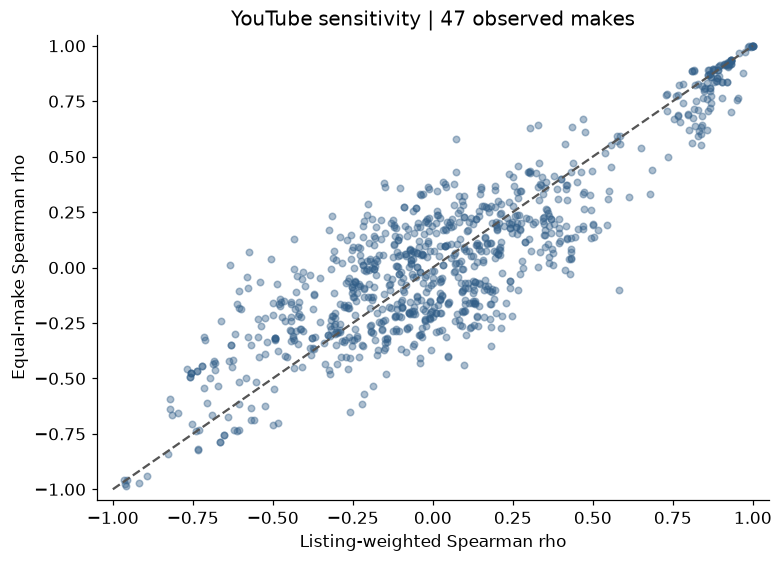

In [5]:
heat_fields = list(dict.fromkeys(strong_pairs[['field_a','field_b']].head(20).to_numpy().ravel()))[:24]
if len(heat_fields)>=2:
    fig,ax = plt.subplots(figsize=(12,10),layout='constrained')
    im = ax.imshow(spearman.loc[heat_fields,heat_fields],cmap='RdBu_r',vmin=-1,vmax=1)
    ax.set_xticks(range(len(heat_fields)),heat_fields,rotation=60,ha='right',fontsize=9)
    ax.set_yticks(range(len(heat_fields)),heat_fields,fontsize=9)
    ax.set_title(f'Observed Spearman correlations | {len(X):,} fit-sample listings')
    fig.colorbar(im,ax=ax,label='Spearman rho',shrink=.7)
    show_figure(fig,'strong_correlations')
else:
    display(Markdown('No sufficiently supported numeric pair crosses the threshold.'))
yt_fields = [c for c in numeric if c in price.YOUTUBE_FEATURE_COLUMNS]
yt_grouped = numbers[yt_fields].assign(Make=make_keys.to_numpy()).dropna(subset=['Make']).groupby('Make')
assert yt_grouped.nunique().max().max() <= 1
yt_make = yt_grouped.first()
yt_corr = yt_make.corr(method='spearman',min_periods=5)
yt_observed = yt_make.notna().to_numpy(dtype=np.int64)
yt_support = yt_observed.T@yt_observed
make_pairs = pairs.loc[pairs.field_a.isin(yt_fields)&pairs.field_b.isin(yt_fields),
                       ['field_a','field_b','observed_pairs','spearman']].copy()
make_pairs['make_spearman'] = [yt_corr.loc[a,b] for a,b in zip(make_pairs.field_a,make_pairs.field_b)]
make_pairs['observed_make_pairs'] = [yt_support[yt_fields.index(a),yt_fields.index(b)] for a,b in zip(make_pairs.field_a,make_pairs.field_b)]
save_table('youtube_make_sensitivity',make_pairs)
display(make_pairs.head(15).round(3))
fig,ax = plt.subplots(figsize=(7,5),layout='constrained')
ax.scatter(make_pairs.spearman,make_pairs.make_spearman,color=BLUE,alpha=.4,s=18)
ax.plot([-1,1],[-1,1],color='#555555',linestyle='--')
ax.set(xlim=(-1.05,1.05),ylim=(-1.05,1.05),xlabel='Listing-weighted Spearman rho',
       ylabel='Equal-make Spearman rho',title=f'YouTube sensitivity | {len(yt_make)} observed makes')
show_figure(fig,'youtube_grain_sensitivity')

### 6. Nominal and mixed-type association
Cramér's V includes a finite-sample/cardinality bias correction. `a_predicts_b` is in-sample modal mapping accuracy from A to B; reverse mapping exposes nested fields. Both can be optimistic for sparse categories. Missing categories are explicit levels. Eta uses observed numeric rows, including categorical missingness as a level; many small groups can inflate eta. These are effect-size screens, not independence claims.

In [6]:
categories = pd.DataFrame({c:price.PricePreprocessor._category(X[c]) for c in categorical})
category_rows = []
for i,a in enumerate(categorical):
    for b in categorical[i+1:]:
        table = pd.crosstab(categories[a],categories[b]).to_numpy(dtype=float)
        total = table.sum()
        nr,nc = table.shape
        v = np.nan
        if nr>1 and nc>1 and total>1:
            chi2 = stats.chi2_contingency(table,correction=False).statistic
            phi2 = max(0,chi2/total-(nr-1)*(nc-1)/(total-1))
            denominator = min(nr-1-(nr-1)**2/(total-1),nc-1-(nc-1)**2/(total-1))
            if denominator>0: v = np.sqrt(phi2/denominator)
        category_rows.append(dict(field_a=a,field_b=b,cramers_v_corrected=v,
            a_predicts_b=table.max(axis=1).sum()/total,b_predicts_a=table.max(axis=0).sum()/total,
            a_levels=nr,b_levels=nc,rows_including_missing=int(total)))
category_pairs = pd.DataFrame(category_rows).sort_values('cramers_v_corrected',ascending=False)
save_table('categorical_pairs',category_pairs)
display(category_pairs.head(20).round(3))
eta_rows = []
for c in categorical:
    grouped = numbers.groupby(categories[c],observed=True)
    means,counts = grouped.mean(),grouped.count()
    within_var = grouped.var(ddof=0).fillna(0)
    grand = (means.fillna(0)*counts).sum()/counts.sum().replace(0,np.nan)
    between = ((means-grand)**2*counts).sum()
    eta = np.sqrt(between/(between+(within_var*counts).sum()).replace(0,np.nan))
    eta_rows.extend(dict(category_field=c,numeric_field=f,eta=eta[f],
        observed_numeric_rows=int(counts[f].sum()),populated_category_levels=int(counts[f].gt(0).sum())) for f in numeric)
eta_pairs = pd.DataFrame(eta_rows)
eta_pairs.loc[eta_pairs.observed_numeric_rows.lt(MIN_PAIR_ROWS),'eta'] = np.nan
eta_pairs = eta_pairs.sort_values('eta',ascending=False)
save_table('category_numeric_pairs',eta_pairs)
display(eta_pairs.head(20).round(3))

,field_a,field_b,cramers_v_corrected,a_predicts_b,b_predicts_a,a_levels,b_levels,rows_including_missing
938,ESC,RearVisibilitySystem,0.991,0.988,0.996,2,4,30000
190,make_name,model_name,0.980,0.252,1.000,47,607,30000
735,AutoReverseSystem,ESC,0.977,0.989,0.983,4,2,30000
250,model_name,BrakeSystemType,0.976,0.991,0.061,607,2,30000
152,is_new,fleet,0.972,0.867,0.986,2,3,30000
149,is_new,has_accidents,0.971,0.902,0.986,2,3,30000
150,is_new,frame_damaged,0.971,0.981,0.986,2,3,30000
151,is_new,salvage,0.971,0.982,0.986,2,3,30000
153,is_new,theft_title,0.971,0.984,0.986,2,3,30000
900,DynamicBrakeSupport,ESC,0.946,0.973,0.964,4,2,30000


,category_field,numeric_field,eta,observed_numeric_rows,populated_category_levels
745,model_name,yt_maintenance_cost_low_confidence_share,1.0,7662,121
744,model_name,yt_maintenance_cost_mean_entropy,1.0,7662,121
717,model_name,yt_maintenance_cost_video_balanced_net,1.0,7662,121
716,model_name,yt_comfort_missing,1.0,30000,607
713,model_name,yt_comfort_video_balanced_net,1.0,4672,59
610,make_name,yt_comfort_mean_confidence,1.0,4672,3
609,make_name,yt_comfort_video_balanced_soft_net,1.0,4672,3
617,make_name,yt_maintenance_cost_mean_entropy,1.0,7662,5
593,make_name,yt_maintenance_cost_missing,1.0,30000,47
589,make_name,yt_comfort_missing,1.0,30000,47


### 7. VIF, rank and condition indices by feature variant
The production `PricePreprocessor` fits on the diagnostic sample: median numeric imputation, categorical tokens and one missing indicator per numeric input. Sample-constant design columns are recorded and excluded only from the matrix calculation. Partially observed constants may still carry informative missingness.

Eigenvalues <= `1e-10 × largest eigenvalue` count as numerically singular (standardized condition index >=100,000). Columns participating in these directions get infinite VIF. Condition indices exclude the centered intercept. Dependencies with condition index >=30 export leading eigenvector weights and variance-decomposition proportions; singular proportions use the numerical tolerance as an eigenvalue floor and require caution.

In [7]:
def design_diagnostics(data,label):
    values = data.to_numpy(dtype=float)
    if not np.isfinite(values).all(): raise ValueError(f'Nonfinite design: {label}')
    scale = values.std(axis=0)
    active = scale>1e-12
    constants = list(data.columns[~active])
    names = np.asarray(data.columns[active])
    if not len(names): raise ValueError(f'No variable design columns: {label}')
    z = (values[:,active]-values[:,active].mean(axis=0))/scale[active]
    with threadpool_limits(limits=4):
        eigenvalues,vectors = np.linalg.eigh(z.T@z/len(z))
    eigenvalues = np.maximum(eigenvalues,0)
    tolerance = eigenvalues[-1]*1e-10
    null = eigenvalues<=tolerance
    alias_weight = (vectors[:,null]**2).sum(axis=1)
    vif = np.maximum(1,((vectors[:,~null]**2)/eigenvalues[~null]).sum(axis=1))
    vif[alias_weight>1e-8] = np.inf
    with np.errstate(divide='ignore'):
        condition = np.sqrt(eigenvalues[-1]/eigenvalues)
    spectrum = pd.DataFrame(dict(direction=np.arange(1,len(names)+1),eigenvalue=eigenvalues,
                                  condition_index=condition,numerically_singular=null))
    variance = vectors**2/np.maximum(eigenvalues,tolerance)
    proportions = variance/variance.sum(axis=1,keepdims=True)
    dependencies = []
    for k in np.flatnonzero(condition>=30):
        for j in np.argsort(np.abs(vectors[:,k]))[-8:][::-1]:
            dependencies.append(dict(direction=int(k+1),condition_index=condition[k],design_field=names[j],
                standardized_direction_weight=vectors[j,k],variance_decomposition_proportion=proportions[j,k]))
    result = pd.DataFrame(dict(design_field=names,vif=vif,alias_weight=alias_weight)).sort_values('vif',ascending=False)
    summary = dict(design=label,rows=len(data),active_columns=len(names),rank=int((~null).sum()),
                   nullity=int(null.sum()),constant_columns=constants,
                   max_finite_condition_index=float(condition[np.isfinite(condition)].max()))
    return result,spectrum,pd.DataFrame(dependencies),summary

# Check against independent auxiliary OLS, plus exact alias and scale-invariance cases.
rng = np.random.default_rng(SEED)
check_data = pd.DataFrame(rng.normal(size=(1200,4)),columns=list('abcd'))
check_data['d'] = .8*check_data.a+.2*check_data.d
check_vif,_,_,_ = design_diagnostics(check_data,'finite_check')
for c in check_data:
    target = check_data[c].to_numpy()
    auxiliary = np.column_stack([np.ones(len(target)),check_data.drop(columns=c).to_numpy()])
    residual = target-auxiliary@np.linalg.lstsq(auxiliary,target,rcond=None)[0]
    expected = ((target-target.mean())**2).sum()/(residual**2).sum()
    assert np.isclose(check_vif.set_index('design_field').loc[c,'vif'],expected,rtol=1e-7)
alias_vif,_,_,alias_summary = design_diagnostics(check_data.assign(copy_a=check_data.a,constant=1.),'alias_check')
assert np.isinf(alias_vif.set_index('design_field').loc[['a','copy_a'],'vif']).all()
assert alias_summary['nullity']==1 and alias_summary['constant_columns']==['constant']
scaled_vif,_,_,_ = design_diagnostics(check_data*[1,10,.01,100],'scale_check')
assert np.allclose(check_vif.sort_values('design_field').vif,scaled_vif.sort_values('design_field').vif)
assert np.allclose(bh_adjust([.01,.04,.03]),[.03,.04,.04])
checks = dict(finite_vif_matches_auxiliary_ols=True,singular_vif_is_infinite=True,
              constant_detection=True,vif_scale_invariance=True,bh_known_example=True,
              disjoint_vin_partitions=True,no_target_or_identifiers=True)
preprocessor = price.PricePreprocessor(categorical,numeric)
prepared = preprocessor.fit_transform(X)
numeric_design = prepared[numeric+[f'{c}__missing' for c in numeric]].astype(float)
variant_summaries,variant_vifs = [],[]
for variant,fields in price.MODEL_FEATURE_SETS.items():
    if not set(fields).issubset(features): continue
    selected = [c for c in fields if c in numeric]
    selected += [f'{c}__missing' for c in selected]
    vif,spectrum,dependencies,summary = design_diagnostics(numeric_design[selected],variant)
    vif['variant'] = variant
    variant_vifs.append(vif)
    variant_summaries.append(summary)
    save_table(f'{variant}_numeric_vif',vif)
    save_table(f'{variant}_condition_spectrum',spectrum)
    save_table(f'{variant}_dependencies',dependencies)
    if variant=='full':
        full_numeric_vif,full_numeric_spectrum,full_numeric_summary = vif.copy(),spectrum.copy(),summary
variant_vifs = pd.concat(variant_vifs,ignore_index=True)
variant_summary = pd.DataFrame(variant_summaries)
save_table('variant_design_summary',variant_summary)
display(variant_summary[['design','rows','active_columns','rank','nullity']])
display(full_numeric_vif.head(25).round(3))

,design,rows,active_columns,rank,nullity
0,base,30000,34,24,10
1,enhanced,30000,71,61,10
2,enhanced_safety,30000,109,88,21
3,full_youtube,30000,183,134,49
4,full_youtube_sentiment,30000,183,134,49
5,enhanced_safety_expert,30000,131,100,31
6,enhanced_safety_expert_coverage,30000,113,91,22
7,full_youtube_expert_coverage,30000,187,137,50
8,full,30000,205,146,59
9,enriched,30000,109,88,21


,design_field,vif,alias_weight,variant
60,yt_semantic_01,inf,0.000,full
72,yt_reliability_mention_share,inf,0.000,full
71,yt_technology_mention_share,inf,0.000,full
70,yt_comfort_mention_share,inf,0.000,full
73,yt_maintenance_cost_mention_share,inf,0.000,full
69,yt_performance_mention_share,inf,0.000,full
68,yt_design_mention_share,inf,0.001,full
67,yt_semantic_08,inf,0.000,full
65,yt_semantic_06,inf,0.000,full
64,yt_semantic_05,inf,0.000,full


### 8. Mixed design with reference-coded categories
Include every categorical field with `min_frequency=20`, at most 12 frequency-ranked levels (including the infrequent pool), and one dropped reference. Export the encoding. Reference coding avoids the artificial full-dummy-plus-intercept trap. Production classical models use `min_frequency=20` without this cap or dropped reference; their VIF/rank may differ. Ridge/Lasso can fit redundant designs but coefficient identification still needs care.

These are **per-column VIFs, not categorical-term GVIFs**. A large dummy VIF is not a whole-field removal rule. Tree models and PCR use different representations. Constant pooled fields are recorded, not silently removed from the field inventory.

,design,rows,active_columns,rank,nullity,max_finite_condition_index
0,full_reference_pooled,30000,416,340,76,3.863449e+09


,design_field,vif,alias_weight
399,BodyCabType_infrequent_sklearn,inf,0.001
397,BodyCabType_value:Not Applicable,inf,0.500
391,BedType_value:Not Applicable,inf,0.500
326,DynamicBrakeSupport_value:Not Available,inf,0.500
63,yt_semantic_04,inf,0.006
62,yt_semantic_03,inf,0.003
61,yt_semantic_02,inf,0.010
60,yt_semantic_01,inf,0.004
59,yt_video_count,inf,0.060
58,yt_eligible_count,inf,0.484


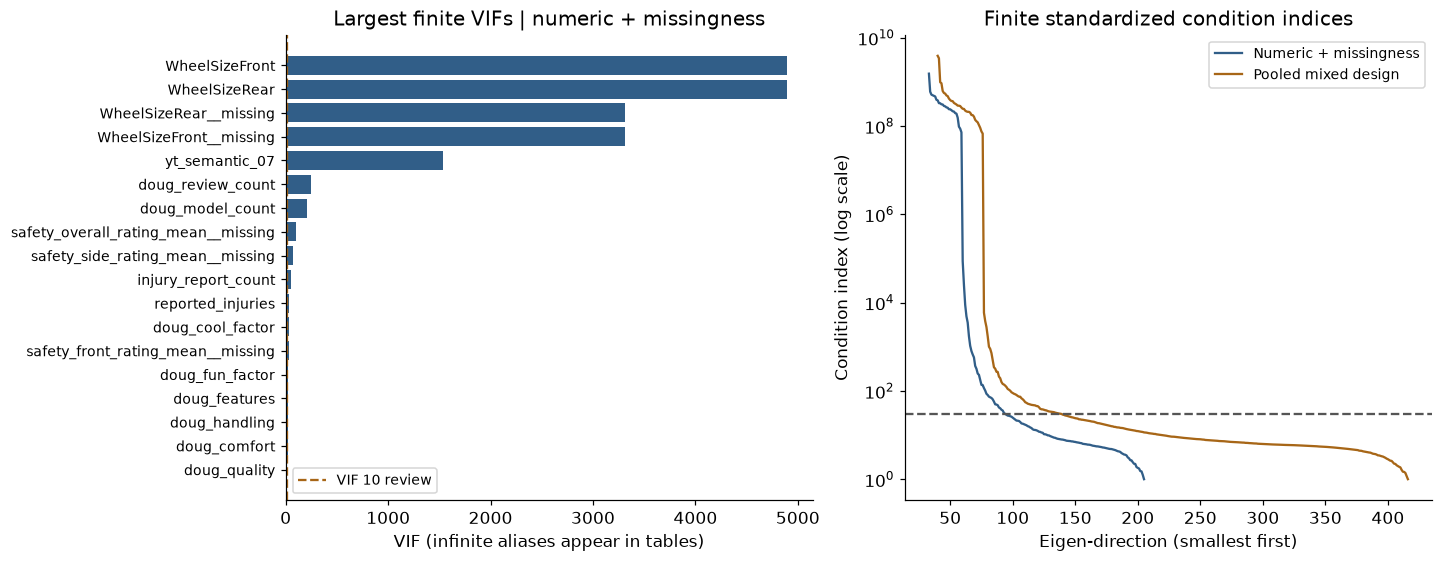

2827

In [8]:
encoder = OneHotEncoder(handle_unknown='ignore',min_frequency=20,max_categories=MAX_CATEGORY_LEVELS,
                        drop='first',sparse_output=False)
encoded = encoder.fit_transform(categories)
dummy_names = list(encoder.get_feature_names_out(categorical))
if len(dummy_names)+numeric_design.shape[1]>MAX_MIXED_COLUMNS:
    raise ValueError('Mixed design exceeds budget; deliberately revise pooling/budget and rerun.')
mixed = pd.concat([numeric_design.reset_index(drop=True),pd.DataFrame(encoded,columns=dummy_names)],axis=1)
mixed_vif,mixed_spectrum,mixed_dependencies,mixed_summary = design_diagnostics(mixed,'full_reference_pooled')
save_table('mixed_design_vif',mixed_vif)
save_table('mixed_condition_spectrum',mixed_spectrum)
save_table('mixed_dependencies',mixed_dependencies)
write_json('mixed_encoding.json',dict(max_categories=MAX_CATEGORY_LEVELS,min_frequency=20,drop='first',
    categories={c:list(map(str,v)) for c,v in zip(categorical,encoder.categories_)},
    infrequent_categories={c:None if v is None else list(map(str,v)) for c,v in zip(categorical,encoder.infrequent_categories_)},
    summary=mixed_summary))
display(pd.DataFrame([{k:v for k,v in mixed_summary.items() if k!='constant_columns'}]))
display(mixed_vif.head(25).round(3))
fig,axes = plt.subplots(1,2,figsize=(13,5),layout='constrained')
finite_vif = full_numeric_vif.loc[np.isfinite(full_numeric_vif.vif)].head(18).sort_values('vif')
axes[0].barh(finite_vif.design_field,finite_vif.vif,color=BLUE)
axes[0].axvline(VIF_HIGH,color=GOLD,linestyle='--',label=f'VIF {VIF_HIGH:g} review')
axes[0].set(title='Largest finite VIFs | numeric + missingness',xlabel='VIF (infinite aliases appear in tables)')
axes[0].tick_params(axis='y',labelsize=9)
axes[0].legend(fontsize=9)
for spectrum,label,color in [(full_numeric_spectrum,'Numeric + missingness',BLUE),(mixed_spectrum,'Pooled mixed design',GOLD)]:
    finite = spectrum.loc[np.isfinite(spectrum.condition_index)]
    axes[1].plot(finite.direction,finite.condition_index,label=label,color=color)
axes[1].axhline(30,color='#555555',linestyle='--')
axes[1].set(yscale='log',title='Finite standardized condition indices',xlabel='Eigen-direction (smallest first)',ylabel='Condition index (log scale)')
axes[1].legend(fontsize=9)
show_figure(fig,'vif_condition_diagnostics')
del mixed,encoded
gc.collect()

### 9. Feature review and model-specific implications
Only all-missing or fully constant **full-fit** fields become immediate exclusion candidates. Sample-exact duplicates remain review candidates until full-fit equality and source meaning are verified. A constant observed measurement with varying missingness can still carry coverage information.

Review correlated groups jointly: **do not delete every member**. Prefer a representative with sound source meaning, timing, support and measurement quality. High eta/category mapping also needs a cardinality check. Unflagged fields mean retain pending validation, not proven usefulness. Mixed-dummy VIF is exported separately rather than converted into an automatic whole-category removal rule.

In [9]:
def strongest_pairs(table,left,right,value):
    forward = table[[left,right,value]].copy()
    backward = table[[right,left,value]].copy()
    forward.columns = backward.columns = ['field','partner','strength']
    long = pd.concat([forward,backward],ignore_index=True).dropna(subset=['strength'])
    long['magnitude'] = long.strength.abs()
    return long.sort_values('magnitude',ascending=False).drop_duplicates('field').set_index('field')
numeric_best = strongest_pairs(pairs,'field_a','field_b','max_abs_correlation')
category_best = strongest_pairs(category_pairs,'field_a','field_b','cramers_v_corrected')
eta_best = strongest_pairs(eta_pairs,'category_field','numeric_field','eta')
duplicate_rows,buckets = [],{}
for c in features:
    values = X[c].astype('string')
    digest = hashlib.sha256(pd.util.hash_pandas_object(values,index=False).values.tobytes()).hexdigest()
    for other in buckets.get(digest,[]):
        if values.equals(X[other].astype('string')):
            duplicate_rows.append(dict(field_a=other,field_b=c,scope='diagnostic fit sample only'))
    buckets.setdefault(digest,[]).append(c)
duplicates = pd.DataFrame(duplicate_rows,columns=['field_a','field_b','scope'])
save_table('sample_exact_duplicates',duplicates)
duplicate_fields = set(duplicates.field_a)|set(duplicates.field_b)
review = profile.copy()
for label,best in [('numeric',numeric_best),('categorical',category_best),('eta',eta_best)]:
    review[f'{label}_partner'],review[f'{label}_strength'] = best.partner.reindex(review.index),best.strength.reindex(review.index)
review['numeric_design_vif'] = full_numeric_vif.set_index('design_field').vif.reindex(review.index)
review['sample_exact_duplicate'] = review.index.isin(duplicate_fields)
actions,reasons = [],[]
for field,row in review.iterrows():
    evidence = []
    if row.fit_status in ('all_missing','constant_including_missingness'):
        action = 'exclusion_candidate'
        evidence.append(row.fit_status+' throughout fitting population; verify domain/availability')
    else:
        if row.sample_exact_duplicate: evidence.append('exact duplicate in diagnostic sample')
        if row.numeric_strength>=CORRELATION_THRESHOLD: evidence.append('strong numeric overlap')
        if row.categorical_strength>=ASSOCIATION_THRESHOLD: evidence.append('strong category association')
        if row.eta_strength>=ASSOCIATION_THRESHOLD: evidence.append('strong category-numeric association; check cardinality')
        if row.numeric_design_vif>=VIF_REVIEW: evidence.append('high or numerically singular numeric VIF')
        if row.fit_missing_share>=.8: evidence.append('at least 80% missing; assess supported subgroup')
        if row.sample_distinct_observed<=1: evidence.append('sample lacks observed variation')
        if row.fit_status=='constant_observed_with_missingness': evidence.append('observed constant; coverage may be informative')
        action = 'review_jointly' if evidence else 'retain_pending_validation'
    actions.append(action)
    reasons.append('; '.join(evidence) or 'no configured redundancy screen triggered')
review['action'],review['reason'] = actions,reasons
save_table('feature_review',review.reset_index())
display(review.groupby('action').size().rename('fields').to_frame())
display(review.loc[review.action.eq('exclusion_candidate'),['fit_status','fit_missing_share','reason']])
display(review.loc[review.action.eq('review_jointly'),['numeric_partner','numeric_strength','numeric_design_vif','reason']].head(25).round(3))
guidance = pd.DataFrame([
    ('multiple_linear_regression','Highest sensitivity to aliases/high VIF. Review reference coding and joint dependencies; compare reduced designs.'),
    ('ridge','Penalty stabilizes correlated coefficients. Tune penalty; validate group removal.'),
    ('lasso','May choose correlated members unstably. Check selection stability across fit resamples.'),
    ('elastic_net','Can retain correlated groups. Tune both penalties; assess group contribution.'),
    ('pcr','Numeric PCs reduce numeric overlap; bypassed categories/flags/missingness can remain aliased. Variance is not price usefulness.'),
    ('random_forest','Correlated fields can substitute. Prefer joint group ablation to VIF-based deletion.'),
    ('catboost','Native categories/nonlinear splits differ from this design. Validate correlated-group ablations.'),
    ('lightgbm','VIF does not diagnose tree prediction quality. Compare group removal on matched validation rows.'),
    ('xgboost','VIF does not diagnose tree prediction quality. Compare group removal on matched validation rows.')
],columns=['estimator','interpretation_and_next_check'])
save_table('model_guidance',guidance)
display(guidance)
variant_reviews = []
for variant in variant_summary.design:
    fields = list(price.MODEL_FEATURE_SETS[variant])
    part = review.loc[fields].reset_index().rename(columns={'numeric_design_vif':'full_numeric_design_vif'})
    part['variant'] = variant
    own_vif = variant_vifs.loc[variant_vifs.variant.eq(variant)].set_index('design_field').vif
    part['variant_numeric_design_vif'] = part.field.map(own_vif)
    variant_reviews.append(part)
save_table('variant_feature_review',pd.concat(variant_reviews,ignore_index=True))

,fields
action,
exclusion_candidate,2
retain_pending_validation,36
review_jointly,139


,fit_status,fit_missing_share,reason
field,,,
yt_feature_row_present,constant_including_missingness,0.0,constant_including_missingness throughout fitt...
yt_performance_missing,constant_including_missingness,0.0,constant_including_missingness throughout fitt...


,numeric_partner,numeric_strength,numeric_design_vif,reason
field,,,,
engine_type,NaN,NaN,NaN,strong category-numeric association; check car...
exterior_color,NaN,NaN,NaN,strong category-numeric association; check car...
horsepower,EngineCylinders,0.851,7.357,strong category-numeric association; check car...
interior_color,NaN,NaN,NaN,strong category-numeric association; check car...
is_new,NaN,NaN,NaN,strong category association; strong category-n...
make_name,NaN,NaN,NaN,strong category association; strong category-n...
model_name,NaN,NaN,NaN,strong category association; strong category-n...
trim_name,NaN,NaN,NaN,strong category association; strong category-n...
wheel_system,NaN,NaN,NaN,strong category association


,estimator,interpretation_and_next_check
0,multiple_linear_regression,Highest sensitivity to aliases/high VIF. Revie...
1,ridge,Penalty stabilizes correlated coefficients. Tu...
2,lasso,May choose correlated members unstably. Check ...
3,elastic_net,Can retain correlated groups. Tune both penalt...
4,pcr,Numeric PCs reduce numeric overlap; bypassed c...
5,random_forest,Correlated fields can substitute. Prefer joint...
6,catboost,Native categories/nonlinear splits differ from...
7,lightgbm,VIF does not diagnose tree prediction quality....
8,xgboost,VIF does not diagnose tree prediction quality....


## Takeaways
### 10. Executed findings and selection boundary
`feature_review.csv` provides the full-set review queue; pair/design tables explain each flag. `variant_feature_review.csv` retains full-set screening actions for context alongside each variant's own VIF. A flagged full-set partner may be absent from a smaller variant: inspect its actual design before applying the flag. Subtype populations need separate reruns, rather than treating this all-listing screen as their evidence.

Before adopting a smaller dataset, verify constants/duplicates against sources, choose a representative from each redundant group and refit the relevant estimators on identical fitting VINs. Compare original/reduced **validation** USD MAE/RMSE and make/year/price-band errors. Freeze the choice before final untouched testing. This notebook does not claim that an ablation or a predictive improvement has been demonstrated.

In [10]:
checks.update(all_features_reviewed=set(review.index)==set(features),
              diagnostic_sample_is_fit_only=len(X)==count,
              all_numeric_missing_indicators_present=all(f'{c}__missing' in numeric_design for c in numeric),
              make_fields_constant_within_make=True,
              stable_sources=all((p.stat().st_size,p.stat().st_mtime_ns)==source_stats[str(p)] for p in source_paths))
assert all(checks.values()),checks
write_json('validation.json',checks)
manifest.update(status='completed',completed_at=datetime.now(timezone.utc).isoformat(),
                action_counts={k:int(v) for k,v in review.action.value_counts().items()},
                strong_numeric_pairs=len(strong_pairs),
                strong_categorical_pairs=int(category_pairs.cramers_v_corrected.ge(ASSOCIATION_THRESHOLD).sum()),
                numeric_rank=full_numeric_summary['rank'],numeric_columns=full_numeric_summary['active_columns'],
                mixed_rank=mixed_summary['rank'],mixed_columns=mixed_summary['active_columns'])
manifest['artifact_sha256'] = {p.name:price.file_sha256(p) for p in RUN.iterdir() if p.is_file() and p.name!='manifest.json'}
write_json('manifest.json',manifest)
display(Markdown(f'''**Executed:** {len(features)} selected inputs; {len(fit_idx):,} fit listings; {len(X):,} diagnostic listings.

- **{len(strong_pairs):,} numeric pairs** reach |r| or |rho| >= {CORRELATION_THRESHOLD:.2f} with >= {MIN_PAIR_ROWS} observed pairs.
- Numeric + missingness rank: **{full_numeric_summary['rank']} / {full_numeric_summary['active_columns']}** after sample-constant removal.
- Pooled reference-coded mixed rank: **{mixed_summary['rank']} / {mixed_summary['active_columns']}**; pooling can change dependencies.
- **{int(review.action.eq('exclusion_candidate').sum())} exclusion candidates** are all missing or constant in the complete fit population; **{int(review.action.eq('review_jointly').sum())} fields** need joint review.

These results flag overlap, not predictive usefulness. Selected features and fitted models remain unchanged. Outputs: `{RUN}`.'''))

**Executed:** 177 selected inputs; 1,660,076 fit listings; 30,000 diagnostic listings.

- **584 numeric pairs** reach |r| or |rho| >= 0.90 with >= 100 observed pairs.
- Numeric + missingness rank: **146 / 205** after sample-constant removal.
- Pooled reference-coded mixed rank: **340 / 416**; pooling can change dependencies.
- **2 exclusion candidates** are all missing or constant in the complete fit population; **139 fields** need joint review.

These results flag overlap, not predictive usefulness. Selected features and fitted models remain unchanged. Outputs: `E:\DataScience_Capstone_Cars\MODEL_OUTPUT\multicollinearity\20261028T020827206815Z`.